# P2.20 — Smaller households: what they added to demand, and do they go with where prices rose?

**Questions:** RQ3.4 (how households evolved relative to population, and how household size changed) and RQ3.5 (the
single-person part). `p2_05` has households against dwellings and `p2_11` ageing; `p2_11` said there was no
single-person split. There is one, but only for the two censuses (2011 and 2021): households by number of persons
(`ine_households_size`) against the resident population of the same years.

**Method.** Between the censuses the change in households is split exactly into the part that population growth
would give at the 2011 persons per household and the part due to the change of household size
(`analysis/household_size.py`). Then the 2011-2021 change in the one-person share is set against the change of
price-to-income 2016-2024 across mainland municipalities.

**Reading rule, fixed before looking:** the one-person share "matters" for the change in price-to-income if its
coefficient keeps its sign and is below p = 0.05 within district, with coast and density class, and with the
change in the 65+ share and the foreign-resident share. A one-person household is a household, not a person
living alone in a home of their own choice; the census year gap (2011 to 2021) is not the price window (2016 to
2024), so this is a cross-section of two different decades' changes. Associations, not effects.

In [1]:
import pandas as pd

from pthousing.analysis import age_structure as ag
from pthousing.analysis import household_size as hs
from pthousing.analysis import supply
from pthousing.data import build_panel, interim, typology
from pthousing.viz import charts, style

style.apply_style()
START, END = 2016, 2024
panel = build_panel.read("panel_municipality_year")
households = interim.read("ine_households_size")
counts = ag.band_counts(ag.read_population())
shares = ag.band_shares(counts)
ty = typology.read().set_index("muni_code")
ty["coast"] = ty["coast_class"].replace({"estuary": "coast"})
ty["segment"] = ty["coast"] + " / " + ty["density_class"]
prof = hs.profile(households, counts)
split = hs.decompose(prof)

## Step 1 — The national picture
Households grew 2.6% on a population that grew 0.4%: most of the new households are smaller households.

In [2]:
nat = hs.aggregate(prof).loc["Portugal"]
parts = split[["households_change_n", "from_population_n", "from_size_n"]].sum()
national = pd.DataFrame(
    {
        "2011": [
            nat["households_2011_n"],
            nat["population_2011_n"],
            nat["persons_per_household_2011"],
            nat["one_person_2011_pct"],
        ],
        "2021": [
            nat["households_2021_n"],
            nat["population_2021_n"],
            nat["persons_per_household_2021"],
            nat["one_person_2021_pct"],
        ],
    },
    index=["households_n", "population_n", "persons_per_household", "one_person_pct"],
)
bysize = (
    households.pivot_table(
        index="size", columns="census_year", values="households_n", aggfunc="sum"
    )
    .assign(change_n=lambda t: t[2021] - t[2011])
    .rename(columns={2011: "households_2011_n", 2021: "households_2021_n"})
)
style.save_table(national.round(3).reset_index(names="measure"), "p2", "household_size_national")
style.save_table(bysize.reset_index(), "p2", "households_by_size_national")
print(national.round(3).to_string())
print(parts.round(0).to_string())
bysize

                               2011          2021
households_n           4.043726e+06  4.149096e+06
population_n           1.055895e+07  1.059912e+07
persons_per_household  2.611000e+00  2.555000e+00
one_person_pct         2.143600e+01  2.477300e+01
households_change_n    105370.0
from_population_n       22282.0
from_size_n             83088.0


census_year,households_2011_n,households_2021_n,change_n
size,,,
1,866827,1027871,161044
2,1277558,1382996,105438
3,965781,894451,-71330
4plus,933560,843778,-89782


## Step 2 — By kind of place: where did households grow without people?
Sums by coast and density class, per 1,000 households of 2011.

In [3]:
seg = split.merge(ty[["segment"]], left_on="muni_code", right_index=True)
sums = seg.groupby("segment")[["households_change_n", "from_population_n", "from_size_n"]].sum()
base = (
    prof.merge(ty[["segment"]], left_on="muni_code", right_index=True)
    .groupby("segment")["households_2011_n"]
    .sum()
)
per_1000 = sums.mul(1000).div(base, axis=0)
groups = hs.aggregate(prof, ty["segment"])
by_segment = pd.concat(
    [
        base.rename("households_2011_n"),
        per_1000.rename(columns=lambda c: c.replace("_n", "_per_1000")),
        groups[
            [
                "persons_per_household_2011",
                "persons_per_household_2021",
                "one_person_2011_pct",
                "one_person_2021_pct",
                "one_person_change_pp",
            ]
        ],
    ],
    axis=1,
).round(1)
style.save_table(by_segment.reset_index(), "p2", "household_size_by_class")
by_segment

,households_2011_n,households_change_per_1000,from_population_per_1000,from_size_per_1000,persons_per_household_2011,persons_per_household_2021,one_person_2011_pct,one_person_2021_pct,one_person_change_pp
segment,,,,,,,,,
coast / intermediate,695673,59.7,48.7,11.0,2.7,2.6,20.8,24.0,3.1
coast / rural,179435,14.0,12.2,1.8,2.6,2.5,22.8,26.3,3.5
coast / urban,1287678,36.8,49.3,-12.4,2.5,2.5,24.9,27.7,2.8
inland / intermediate,592114,24.0,-33.3,57.3,2.8,2.6,17.2,21.1,3.9
inland / rural,716664,-45.6,-96.5,50.9,2.5,2.4,22.8,26.7,3.9
inland / urban,572162,56.6,20.4,36.2,2.8,2.7,16.7,20.4,3.6


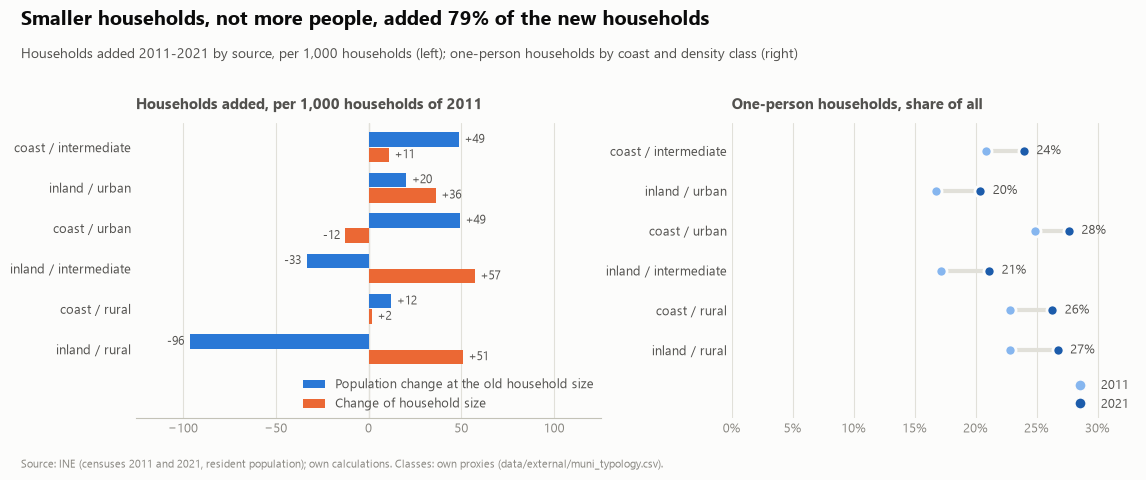

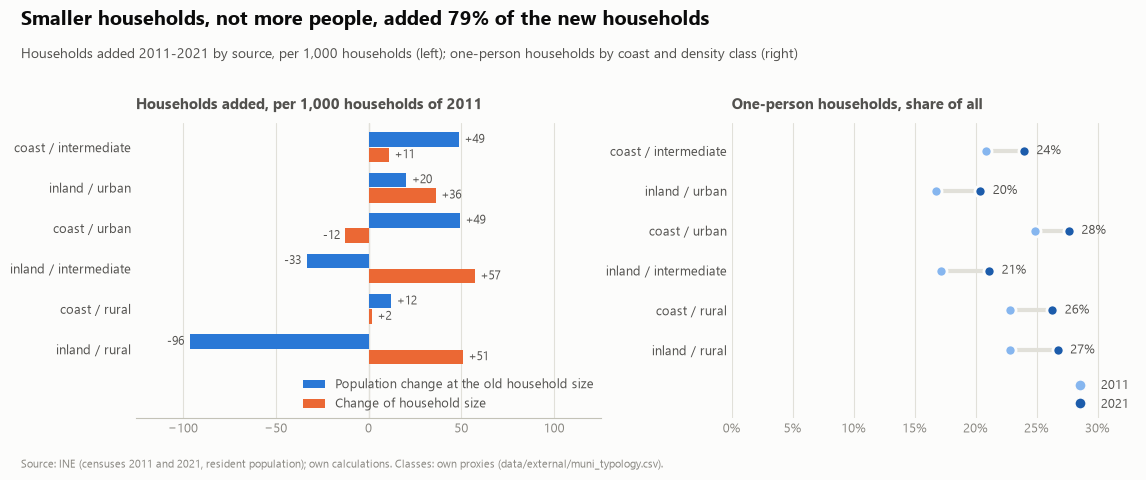

In [4]:
order = per_1000["households_change_n"].sort_values(ascending=False).index
chart_groups = pd.DataFrame(
    {
        "label": order,
        "start": groups.loc[order, "one_person_2011_pct"].to_numpy(),
        "end": groups.loc[order, "one_person_2021_pct"].to_numpy(),
    }
)
fig = charts.household_size_change(
    per_1000.loc[order, ["from_population_n", "from_size_n"]],
    chart_groups,
    100 * parts["from_size_n"] / parts["households_change_n"],
)
style.save_fig(fig, "p2", "household_size")
fig

In [5]:
shrinking = split[split["dlog_population"] < 0]
print(
    f"municipalities losing residents: {len(shrinking)} of {len(split)}; of these, gaining households: "
    f"{(shrinking['dlog_households'] > 0).sum()}; with a smaller average household: "
    f"{(split['dlog_size'] < 0).sum()} of {len(split)}"
)

municipalities losing residents: 239 of 308; of these, gaining households: 72; with a smaller average household: 270 of 308


## Step 3 — One-person share and price-to-income, 2016 to 2024 (mainland, RQ3.5)
Outcome: log change of price-to-income. Drivers: change of the one-person share 2011-2021 (points), the
65+ share 2011-2021 (points) and the foreign-resident share 2016-2023 (points). Same-district comparisons, HC3 errors.

In [6]:
d = prof.set_index("muni_code")[
    ["one_person_change_pp", "size_change", "one_person_2021_pct"]
].join(ty[["coast", "density_class", "territory"]])
age = ag.change_between(shares, 2011, 2021, ["age_65plus_pct"])
d["age_65plus_change_pp"] = age["age_65plus_pct_change_pp"]
d["dlog_pti"] = supply.pti_change(panel, START, END)
d["district"] = supply.area_of(panel)
foreign = panel.pivot(index="muni_code", columns="year", values="foreign_residents_pct")
d["foreign_change_pp"] = foreign[2023] - foreign[2016]
d = d[d["territory"] == "continente"]
ONE, SIZE, OLD, F = (
    "one_person_change_pp",
    "size_change",
    "age_65plus_change_pp",
    "foreign_change_pp",
)
print(d[[ONE, SIZE, OLD, F, "dlog_pti"]].corr().round(2))

                      one_person_change_pp  size_change  age_65plus_change_pp  \
one_person_change_pp                  1.00        -0.48                  0.38   
size_change                          -0.48         1.00                 -0.43   
age_65plus_change_pp                  0.38        -0.43                  1.00   
foreign_change_pp                    -0.36         0.58                 -0.38   
dlog_pti                             -0.16         0.40                 -0.21   

                      foreign_change_pp  dlog_pti  
one_person_change_pp              -0.36     -0.16  
size_change                        0.58      0.40  
age_65plus_change_pp              -0.38     -0.21  
foreign_change_pp                  1.00      0.44  
dlog_pti                           0.44      1.00  


In [7]:
GEO = ["coast", "density_class"]
MODELS = {
    "one-person share, same district": ([ONE], None),
    "one-person share, + coast and density": ([ONE], GEO),
    "one-person share, + 65+ and foreign residents": ([ONE, OLD, F], GEO),
    "persons per household, same district": ([SIZE], None),
    "persons per household, + coast and density": ([SIZE], GEO),
    "persons per household, + 65+ and foreign residents": ([SIZE, OLD, F], GEO),
}
table = pd.concat(
    [
        supply.associations(
            d, "dlog_pti", xs, fixed_effects="district", categorical=cats, label=name
        )
        for name, (xs, cats) in MODELS.items()
    ],
    ignore_index=True,
)
style.save_table(table, "p2", "household_size_associations")
print(
    table[["spec", "term", "coef", "se", "p", "coef_per_sd", "n_obs"]]
    .round(3)
    .to_string(index=False)
)

                                              spec                 term   coef    se     p  coef_per_sd  n_obs
                   one-person share, same district one_person_change_pp -0.016 0.015 0.295       -0.020    271
             one-person share, + coast and density one_person_change_pp -0.007 0.015 0.634       -0.009    271
     one-person share, + 65+ and foreign residents one_person_change_pp  0.001 0.018 0.943        0.002    271
     one-person share, + 65+ and foreign residents age_65plus_change_pp  0.000 0.012 0.976        0.001    271
     one-person share, + 65+ and foreign residents    foreign_change_pp  0.017 0.007 0.019        0.048    271
              persons per household, same district          size_change  0.497 0.173 0.004        0.069    271
        persons per household, + coast and density          size_change  0.247 0.147 0.093        0.035    271
persons per household, + 65+ and foreign residents          size_change  0.146 0.176 0.405        0.020    271
p

## Step 4 — Is the one-person share an ageing story?
The change in the one-person share by third of the 65+ change, and the correlation.

In [8]:
d["old_third"] = pd.qcut(d[OLD], 3, labels=["least ageing", "middle third", "most ageing"])
thirds = (
    d.groupby("old_third", observed=True)
    .agg(
        municipalities_n=(OLD, "size"),
        age_65plus_change_pp=(OLD, "median"),
        one_person_change_pp=(ONE, "median"),
        size_change=(SIZE, "median"),
        pti_change_log=("dlog_pti", "median"),
    )
    .round(3)
    .reset_index()
)
style.save_table(thirds, "p2", "household_size_by_ageing_third")
print("correlation, one-person change and 65+ change:", round(d[ONE].corr(d[OLD]), 2))
thirds

correlation, one-person change and 65+ change: 0.38


,old_third,municipalities_n,age_65plus_change_pp,one_person_change_pp,size_change,pti_change_log
0,least ageing,93,2.367,3.436,-0.064,0.250
1,middle third,92,4.724,3.858,-0.126,0.153
2,most ageing,93,6.498,4.383,-0.173,0.125


## Findings

1. **Households grew 2.6% on a population that grew 0.4% (RQ3.4).** 4.04 million households in 2011, 4.15 million in
   2021 (+105,000), residents 10.56 to 10.60 million; persons per household fell from 2.61 to 2.55. Of the added
   households, 22,000 (21%) are what the population change gives at the 2011 size and 83,000 (79%) come from smaller
   households.
2. **The one-person household is the growing kind.** One-person households 867,000 to 1,028,000 (+161,000; 21.4% to
   24.8% of households), two-person +105,000, three-person −71,000, four or more −90,000.
3. **Households grew without people in the interior.** 239 of 308 municipalities lost residents, 72 of them still
   gained households, and 270 had a smaller average household. Per 1,000 households of 2011, inland rural lost 96
   from population and gained 51 from size, inland intermediate −33 and +57; coastal urban gained 49 from
   population and lost 12 to larger households (persons per household 2.5 in both censuses).
4. **The one-person share does not go with the rise in price-to-income (RQ3.5).** −1.6% per point (p = 0.30) in the
   same district, −0.7% (p = 0.63) with coast and density, +0.1% (p = 0.94) with the 65+ and foreign-resident
   changes. By the reading rule fixed in advance it does not matter. The foreign-resident change stays positive
   (+1.4% to +1.7% per point, p = 0.02 to 0.05).
5. **Persons per household goes the other way and fades.** Where the average household grew (or shrank less),
   price-to-income rose more: +0.50 log points per person in the same district (p = 0.004), +0.25 with coast and
   density (p = 0.09), +0.15 with the age and migrant controls (p = 0.41). Larger households sit with the
   migrant-receiving places, not an independent signal.
6. **The one-person share is partly an ageing story.** Its change was 3.4 points in the third of municipalities
   that aged least and 4.4 in the third that aged most (correlation with the 65+ change 0.38); the median log rise
   of price-to-income was 0.25 against 0.13.

**Limits.** Two census years only, nothing between; persons per household divides all residents (collective homes
included) by private households; a one-person household is not a measure of choice or of unmet demand; the household
change (2011-2021) and the price window (2016-2024) differ; 271 mainland municipalities, one cross-section.
Associations, not effects.